In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget
#plt.rcParams.update({'font.size': 30})
SMALL_SIZE = 9
MEDIUM_SIZE = 9
BIGGER_SIZE = 14
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc('figure', autolayout=True) 

## SMAPE Scores

In [3]:
import glob
path_best = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/best_case/v2/reports"
path_real = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/real_case/v2/reports"
path_worst = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/worst_case/perfect_registration/reports"
paths = [path_best, path_real, path_worst]

In [4]:
for path in paths:
    result_files = glob.glob(path + "/results_summary_*.csv")
    df = pd.read_csv(result_files[0])
    for file in result_files[1:]:
        df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
    print(path)
    columns = ['MRE X', 'MRE Y', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3']
    stats = df[columns].agg(['mean', 'std']).T
    display(stats.apply(lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1))

T:/BMS/new_Databackup/Jan/fiscas-validator/palma/best_case/v2/reports


MRE X    1.3269 ± 0.1075
MRE Y    1.2487 ± 0.1750
m/z 0    0.0115 ± 0.0030
m/z 1    0.0100 ± 0.0013
m/z 2    0.0146 ± 0.0053
m/z 3    0.0368 ± 0.0122
dtype: str

T:/BMS/new_Databackup/Jan/fiscas-validator/palma/real_case/v2/reports


MRE X    2.5739 ± 0.2533
MRE Y    2.5035 ± 0.2302
m/z 0    0.0370 ± 0.0059
m/z 1    0.1186 ± 0.0104
m/z 2    0.1745 ± 0.0149
m/z 3    0.4283 ± 0.0302
dtype: str

T:/BMS/new_Databackup/Jan/fiscas-validator/palma/worst_case/perfect_registration/reports


MRE X    5.0638 ± 0.4600
MRE Y    5.0140 ± 0.4675
m/z 0    0.0785 ± 0.0087
m/z 1    0.1944 ± 0.0151
m/z 2    0.2279 ± 0.0233
m/z 3    0.5407 ± 0.0343
dtype: str

## Histograms

In [5]:
path_best = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/best_case/v2/run_1"
path_real = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/real_case/v2/run_1"
path_worst = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/worst_case/v2/run_1"
paths = [path_best, path_real, path_worst]
scenarios = []
spectra = {}
for i, path in enumerate(paths):
    test_case = path.split("/")[-3]
    scenarios.append(test_case)
    for file in glob.glob(path + "/spectra_comparison_*.npy"):
        mz = file.split("/")[-1].split("_")[-1].split(".")[0]
        key = f"{test_case}_mz{mz}"
        spectra[key] = np.load(file)


In [71]:
scenario_colors = {'best_case': '#440154', 'real_case': '#2A788E', 'worst_case': '#7AD151'}
mz_colors = {'mz0': '#E69F00', 'mz1': '#56B4E9', 'mz2': '#009E73', 'mz3': '#0072B2'} ##F0E442
markers = ['o', 's', '^', 'D']
mz_values = ['mz0', 'mz1', 'mz2', 'mz3']
scenario_label = {'best_case': 'best-case', 'real_case': 'real-case', 'worst_case': 'worst-case'}
mz_label = {'mz0': r'$\mathit{m/z}$ 1', 'mz1': r'$\mathit{m/z}$ 2', 'mz2': r'$\mathit{m/z}$ 3', 'mz3': r'$\mathit{m/z}$ 4'}

### Scenario comparison

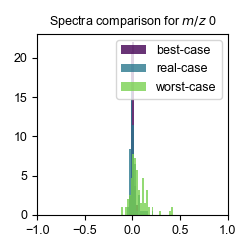

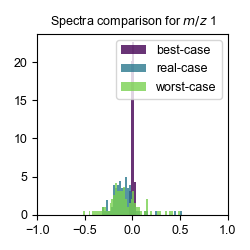

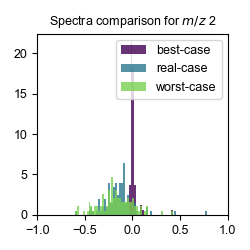

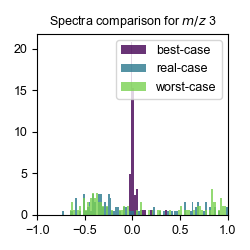

In [72]:
from scipy.stats import gaussian_kde

for mz in mz_values:
    plt.figure(figsize=(2.5, 2.5))
    for scenario in scenarios:
        key = f"{scenario}_{mz}"
        common_data = np.concatenate([spectra[f"{s}_{mz}"] for s in scenarios])
        common_bins = np.histogram_bin_edges([-1,1], bins=100)

        hist, bins = np.histogram(
            spectra[key],
            bins=common_bins,
            density=True
        )


        data = spectra[key][np.isfinite(spectra[key])]
        kde = gaussian_kde(data)
        x_kde = np.linspace(-1, 1, 500)

        # plt.plot(
        #     x_kde,
        #     kde(x_kde),
        #     color=scenario_colors[scenario],
        #     linewidth=2.5,
        #     zorder=3
        # )
        plt.hist(
            bins[:-1],
            bins=bins,
            weights=hist,
            label=scenario_label[scenario],
            color=scenario_colors[scenario],
            alpha=0.8
        )
    plt.xlim(-1,1)
    plt.legend()
    plt.title(r"Spectra comparison for $\mathit{m/z}$ " + f"{mz[-1]}")
    plt.tight_layout()
    plt.savefig(f"./output/plots/histogram_{mz}.svg", bbox_inches='tight', pad_inches=0, dpi=600)
    plt.savefig(f"T:/BMS/new_Databackup/Jan/fiscas-validator/output/plots/histogram_{mz}.svg", bbox_inches='tight', pad_inches=0, dpi=600)

### m/z comparison

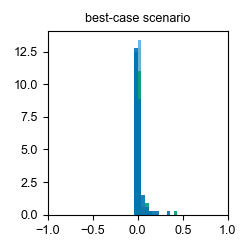

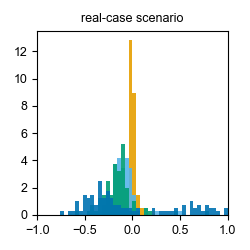

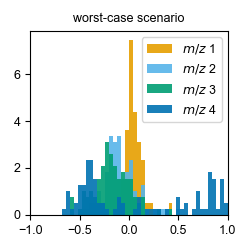

In [73]:
for scenario in scenarios:
    plt.figure(figsize=(2.5, 2.5))
    for mz in mz_values:
        key = f"{scenario}_{mz}"
        common_data = np.concatenate([spectra[f"{s}_{mz}"] for s in scenarios])
        common_bins = np.histogram_bin_edges([-1,1], bins=50)

        hist, bins = np.histogram(
            spectra[key],
            bins=common_bins,
            density=True
        )
        plt.hist(
            bins[:-1],
            bins=bins,
            weights=hist,
            label=mz_label[mz],
            color=mz_colors[mz],
            alpha=0.9
        )


    plt.xlim(-1,1)
    if scenario == 'worst_case':
        plt.legend()
    plt.title(f"{scenario_label[scenario]} scenario")
    plt.tight_layout()
    plt.savefig(f"./output/plots/histogram_{scenario}.svg", bbox_inches='tight', pad_inches=0, dpi=600)
    plt.savefig(f"T:/BMS/new_Databackup/Jan/fiscas-validator/output/plots/histogram_{scenario}.svg", bbox_inches='tight', pad_inches=0, dpi=600)
    

In [74]:
[spectra['best_case_mz2']>0.4]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False,  True,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False])]

In [75]:
import pickle

path = r"T:\BMS\new_Databackup\Jan\fiscas-validator\palma\best_case\v2\run_1\cell_labels.pkl"
path2 = r"T:\BMS\new_Databackup\Jan\fiscas-validator\palma\best_case\v2\run_1\canvas_to_mask.pkl"
path3 = r"T:\BMS\new_Databackup\Jan\fiscas-validator\palma\best_case\v2\run_1\cells.pkl"

with open(path, "rb") as f:
    cell_labels = pickle.load(f)

with open(path2, "rb") as f:
    canvas_to_mask = pickle.load(f)

with open(path3, "rb") as f:
    cells = pickle.load(f)

spectra_comparison = np.load(r"T:\BMS\new_Databackup\Jan\fiscas-validator\palma\best_case\v3\run_2\spectra_comparison_2.npy")
cells

array([[    0.        ,     0.        ,     0.        ,     0.        ],
       [    0.        ,     0.        ,     0.        ,     0.        ],
       [    0.        ,     0.        ,     0.        ,     0.        ],
       ...,
       [    0.        ,     0.        ,     0.        ,     0.        ],
       [13516.77734257, 12904.47826923, 16450.84344968,  4368.33460317],
       [ 3302.57381967,  5343.7783876 ,  9426.76947143,  3501.94937748]],
      shape=(645, 4))

In [51]:
spectra_comparison

array([ 2.82723776e-02, -3.99387070e-02,  3.55223762e-03, -9.01139851e-03,
       -4.49597258e-03,  1.56655464e-02, -1.33024622e-04, -1.64871325e-02,
       -1.86334326e-03, -6.20064257e-03,  2.78126023e-02, -1.19685179e-02,
        2.46087900e-03, -1.81310051e-03, -2.06929704e-02, -5.35077133e-05,
       -9.98516586e-05, -4.90729230e-04,  1.40837414e-03, -4.77984046e-03,
       -4.32707682e-03,  6.97149828e-03, -1.30243914e-02,  2.86156673e-02,
        6.99155084e-03, -1.16928108e-03, -1.79975854e-02,  1.06487217e-02,
       -6.84849475e-03, -3.24160661e-03, -8.80856558e-04, -1.69992863e-03,
        1.05063935e-02, -1.47591476e-03, -9.07245030e-03,  1.11536607e-02,
        5.16926245e-04, -1.90458675e-04,  5.73944001e-03,  5.53403742e-03,
       -1.63470279e-02, -8.03311083e-03,  1.87913183e-02,  1.64696934e-02,
       -2.56518773e-02, -8.68218567e-16, -2.40781980e-03, -1.03054502e-02,
       -1.33368247e-02,  4.09023429e-02, -4.09931739e-03,  5.20443222e-01,
       -1.09035157e-03, -

In [57]:
canvas_to_mask

{7: 7,
 8: 8,
 16: 16,
 17: 17,
 18: 18,
 19: 19,
 20: 20,
 28: 28,
 29: 29,
 30: 30,
 31: 31,
 76: 76,
 77: 77,
 101: 101,
 102: 102,
 103: 103,
 136: 136,
 137: 137,
 138: 138,
 139: 139,
 140: 140,
 145: 145,
 146: 146,
 147: 147,
 148: 148,
 149: 149,
 153: 153,
 154: 154,
 155: 155,
 164: 164,
 165: 165,
 166: 166,
 167: 167,
 168: 168,
 171: 171,
 172: 172,
 173: 173,
 174: 174,
 176: 176,
 177: 177,
 178: 178,
 184: 184,
 185: 185,
 228: 228,
 229: 229,
 242: 242,
 243: 243,
 244: 244,
 245: 245,
 246: 246,
 258: 258,
 267: 267,
 278: 278,
 283: 283,
 284: 284,
 320: 320,
 321: 321,
 322: 322,
 323: 323,
 334: 334,
 336: 336,
 337: 337,
 338: 338,
 339: 339,
 340: 340,
 341: 341,
 375: 375,
 376: 376,
 382: 382,
 383: 383,
 384: 384,
 385: 385,
 386: 386,
 419: 419,
 420: 420,
 421: 421,
 426: 426,
 436: 436,
 485: 485,
 486: 486,
 487: 487,
 496: 496,
 497: 497,
 502: 502,
 503: 503,
 535: 535,
 536: 536,
 537: 537,
 538: 538,
 554: 554,
 555: 555,
 570: 570,
 571: 571,
 584: 5

In [65]:
cell_labels[267]

'B'

In [63]:
spectra['best_case_mz2']

array([ 2.82723776e-02, -3.99387070e-02,  3.55223762e-03, -9.01139851e-03,
       -4.49597258e-03,  1.56655464e-02, -1.33024622e-04, -1.64871325e-02,
       -1.86334326e-03, -6.20064257e-03,  2.78126023e-02, -1.19685179e-02,
        2.46087900e-03, -1.81310051e-03, -2.06929704e-02, -5.35077133e-05,
       -9.98516586e-05, -4.90729230e-04,  1.40837414e-03, -4.77984046e-03,
       -4.32707682e-03,  6.97149828e-03, -1.30243914e-02,  2.86156673e-02,
        6.99155084e-03, -1.16928108e-03, -1.79975854e-02,  1.06487217e-02,
       -6.84849475e-03, -3.24160661e-03, -8.80856558e-04, -1.69992863e-03,
        1.05063935e-02, -1.47591476e-03, -9.07245030e-03,  1.11536607e-02,
        5.16926245e-04, -1.90458675e-04,  5.73944001e-03,  5.53403742e-03,
       -1.63470279e-02, -8.03311083e-03,  1.87913183e-02,  1.64696934e-02,
       -2.56518773e-02, -8.68218567e-16, -2.40781980e-03, -1.03054502e-02,
       -1.33368247e-02,  4.09023429e-02, -4.09931739e-03,  5.20443222e-01,
       -1.09035157e-03, -

In [ ]:
np.asarray(list(cell_labels.keys()))[spectra['best_case_mz2']>0.4]

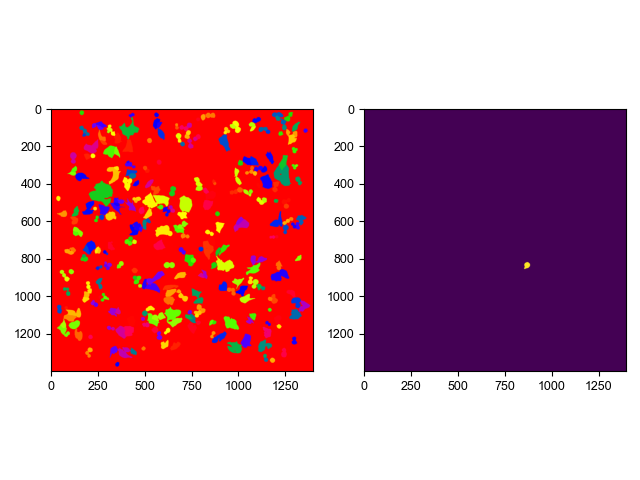

In [54]:
import skimage
masks = skimage.io.imread("T:/BMS/new_Databackup/Jan/fiscas-validator/palma/best_case/v3/run_2/mask_canvas.tiff")
fig, ax = plt.subplots(1,2)
ax[0].imshow(masks, cmap='prism')
img = np.zeros_like(masks)
img[masks == 267] = 1
ax[1].imshow(img)

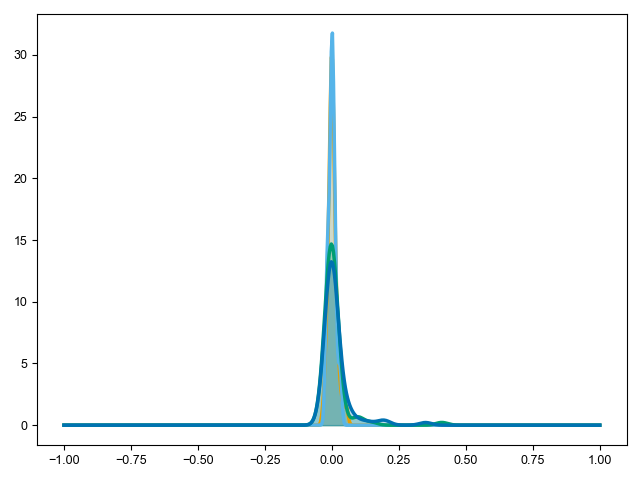

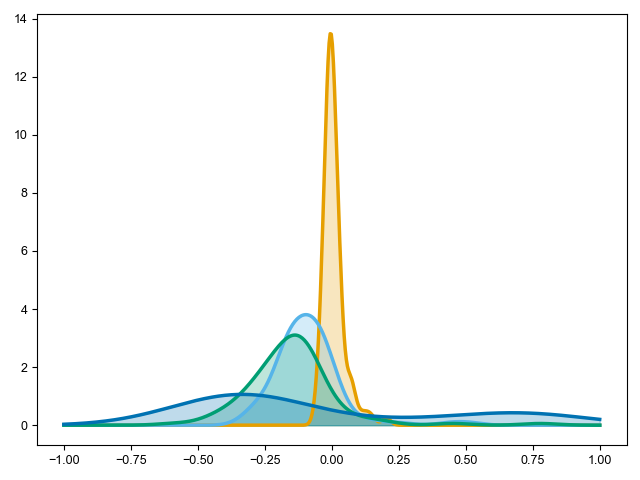

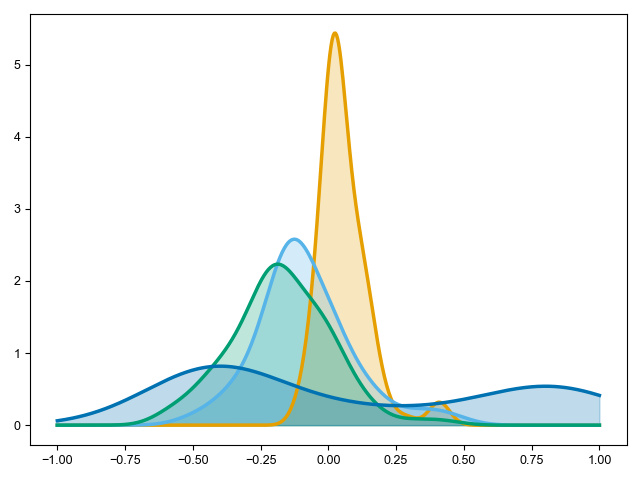

In [67]:
for scenario in scenarios:
    plt.figure()
    for mz in mz_values:

        key = f"{scenario}_{mz}"
        common_data = np.concatenate([spectra[f"{s}_{mz}"] for s in scenarios])
        common_bins = np.histogram_bin_edges([-1,1], bins=100)

        hist, bins = np.histogram(
            spectra[key],
            bins=common_bins,
            density=True
        )
        data = spectra[key][np.isfinite(spectra[key])]
        kde = gaussian_kde(data)
        x_kde = np.linspace(-1, 1, 500)

        plt.plot(
            x_kde,
            kde(x_kde),
            color=mz_colors[mz],
            linewidth=2.5,
            zorder=3
        )
        plt.fill_between(
            x_kde,
            kde(x_kde),
            color=mz_colors[mz],
            alpha=0.25,
            zorder=2
        )